In [6]:
import pandas as pd
d=pd.read_csv('/content/links.csv')
df=pd.DataFrame(d)
df

,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0
...,...,...,...
9737,193581,5476944,432131.0
9738,193583,5914996,445030.0
9739,193585,6397426,479308.0
9740,193587,8391976,483455.0


In [ ]:
for u,v in df.iterrows():


### Similarity Metric Implementation from Scratch & Evaluation

This cell implements:
1. **Raw Cosine Similarity**
2. **Pearson Correlation Coefficient**
3. **Spearman Correlation Coefficient**
4. **Jaccard Similarity**

All implementations are built using basic mathematics and standard vector operations (via `numpy` or basic iteration) without leveraging built-in similarity/correlation functions.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

def get_intersection_ratings(v1, v2):
    """Find indices where both items have non-null/non-zero ratings."""
    mask = (~np.isnan(v1)) & (~np.isnan(v2)) & (v1 > 0) & (v2 > 0)
    return v1[mask], v2[mask]

def raw_cosine_similarity(v1, v2):
    """Compute Raw Cosine Similarity over co-rated items."""
    r1, r2 = get_intersection_ratings(v1, v2)
    if len(r1) == 0:
        return 0.0
    dot_product = np.dot(r1, r2)
    norm_v1 = np.sqrt(np.dot(r1, r1))
    norm_v2 = np.sqrt(np.dot(r2, r2))
    if norm_v1 == 0 or norm_v2 == 0:
        return 0.0
    return dot_product / (norm_v1 * norm_v2)

def pearson_correlation(v1, v2):
    """Compute Pearson Correlation over co-rated items (mean-centered)."""
    r1, r2 = get_intersection_ratings(v1, v2)
    if len(r1) < 2:
        return 0.0
    mean_r1 = np.mean(r1)
    mean_r2 = np.mean(r2)
    diff_r1 = r1 - mean_r1
    diff_r2 = r2 - mean_r2
    num = np.dot(diff_r1, diff_r2)
    den = np.sqrt(np.dot(diff_r1, diff_r1) * np.dot(diff_r2, diff_r2))
    if den == 0:
        return 0.0
    return num / den

def get_ranks(v):
    """Compute fractional ranks for a 1D array."""
    temp = v.argsort()
    ranks = np.empty_like(temp, dtype=float)
    ranks[temp] = np.arange(len(v))
    # Handle ties
    for val in np.unique(v):
        mask = (v == val)
        ranks[mask] = ranks[mask].mean()
    return ranks + 1

def spearman_correlation(v1, v2):
    """Compute Spearman Rank Correlation over co-rated items."""
    r1, r2 = get_intersection_ratings(v1, v2)
    if len(r1) < 2:
        return 0.0
    rank1 = get_ranks(r1)
    rank2 = get_ranks(r2)
    mean_r1 = np.mean(rank1)
    mean_r2 = np.mean(rank2)
    diff_r1 = rank1 - mean_r1
    diff_r2 = rank2 - mean_r2
    num = np.dot(diff_r1, diff_r2)
    den = np.sqrt(np.dot(diff_r1, diff_r1) * np.dot(diff_r2, diff_r2))
    if den == 0:
        return 0.0
    return num / den

def jaccard_similarity(v1, v2):
    """Compute Jaccard Similarity (intersection over union of raters)."""
    raters_v1 = set(np.where((~np.isnan(v1)) & (v1 > 0))[0])
    raters_v2 = set(np.where((~np.isnan(v2)) & (v2 > 0))[0])
    intersection = len(raters_v1.intersection(raters_v2))
    union = len(raters_v1.union(raters_v2))
    if union == 0:
        return 0.0
    return intersection / union

In [8]:
def prepare_rating_matrix(filepath, top_n_items=30):
    df_temp = pd.read_csv(filepath)

    df_temp = df_temp.groupby(['userId', 'movieId'], as_index=False)['rating'].mean()


    popular_items = df_temp['movieId'].value_counts().head(top_n_items).index
    df_filtered = df_temp[df_temp['movieId'].isin(popular_items)]

    pivot_df = df_filtered.pivot(index='userId', columns='movieId', values='rating')
    return pivot_df


def compute_similarity_matrix(pivot_df, metric_fn):
    items = pivot_df.columns
    n = len(items)
    sim_matrix = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            if i == j:
                sim_matrix[i, j] = 1.0
            else:
                v1 = pivot_df.iloc[:, i].values
                v2 = pivot_df.iloc[:, j].values
                sim_matrix[i, j] = metric_fn(v1, v2)
    return pd.DataFrame(sim_matrix, index=items, columns=items)

### Compute and Visualize for Real-world Dataset (`ratings.csv`)

Let's run the similarity metrics on the real-world rating dataset and compare the outcomes visually via Heatmaps.

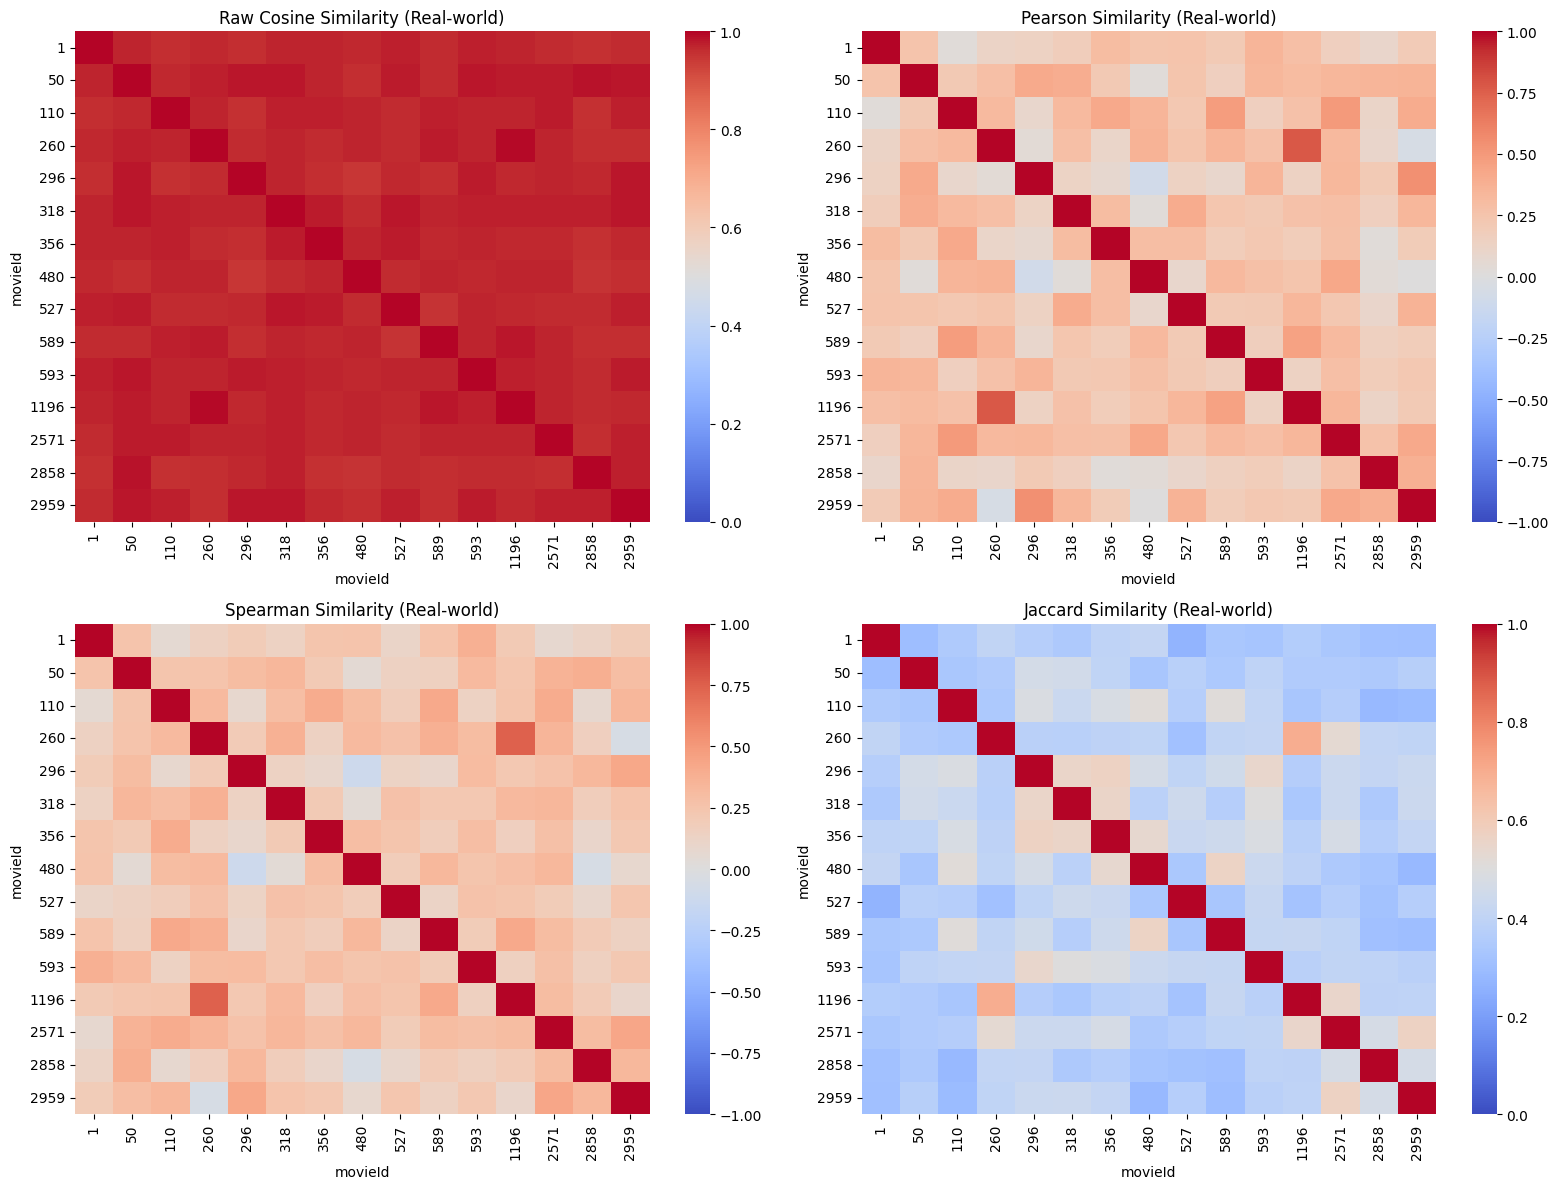

In [9]:

real_world_path = '/root/.cache/kagglehub/datasets/aigamer/movie-lens-dataset/versions/1/ratings.csv'
pivot_real = prepare_rating_matrix(real_world_path, top_n_items=15)

sim_cosine = compute_similarity_matrix(pivot_real, raw_cosine_similarity)
sim_pearson = compute_similarity_matrix(pivot_real, pearson_correlation)
sim_spearman = compute_similarity_matrix(pivot_real, spearman_correlation)
sim_jaccard = compute_similarity_matrix(pivot_real, jaccard_similarity)

# Plot the heatmaps
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
metrics = [('Raw Cosine', sim_cosine), ('Pearson', sim_pearson), ('Spearman', sim_spearman), ('Jaccard', sim_jaccard)]

for ax, (title, matrix) in zip(axes.flatten(), metrics):
    sns.heatmap(matrix, annot=False, cmap='coolwarm', ax=ax, vmin=-1 if title in ['Pearson', 'Spearman'] else 0, vmax=1)
    ax.set_title(f'{title} Similarity (Real-world)')

plt.tight_layout()
plt.show()

In [11]:
synthetic_files = {
    'Normal': '/content/normal_ratings.csv',
    'Uniform': '/content/uniform_ratings.csv',
    'Poisson': '/content/poisson_ratings.csv'
}


def prepare_synthetic_matrix(filepath, top_n_items=10):
    df_temp = pd.read_csv(filepath)
    print(f"Columns found in {os.path.basename(filepath)}: {list(df_temp.columns)}")


    col_mapping = {col: col.lower() for col in df_temp.columns}
    df_temp = df_temp.rename(columns=col_mapping)


    user_col = next((c for c in df_temp.columns if 'user' in c), df_temp.columns[0])
    item_col = next((c for c in df_temp.columns if 'item' in c or 'movie' in c), df_temp.columns[1])
    rating_col = next((c for c in df_temp.columns if 'rate' in c or 'rating' in c), df_temp.columns[2])

    print(f"Using mapping: user -> {user_col}, item -> {item_col}, rating -> {rating_col}")


    df_temp = df_temp.groupby([user_col, item_col], as_index=False)[rating_col].mean()


    popular_items = df_temp[item_col].value_counts().head(top_n_items).index
    df_filtered = df_temp[df_temp[item_col].isin(popular_items)]

    pivot_df = df_filtered.pivot(index=user_col, columns=item_col, values=rating_col)
    return pivot_df

for name, filepath in synthetic_files.items():
    if os.path.exists(filepath):
        print(f"\n--- Processing {name} Rating Matrix ---")
        try:
            pivot_syn = prepare_synthetic_matrix(filepath, top_n_items=10)
            sc = compute_similarity_matrix(pivot_syn, raw_cosine_similarity)
            sp = compute_similarity_matrix(pivot_syn, pearson_correlation)

            item_cols = pivot_syn.columns
            if len(item_cols) > 1:
                i1, i2 = item_cols[0], item_cols[1]
                v1 = pivot_syn[i1].values
                v2 = pivot_syn[i2].values
                print(f"Item {i1} vs Item {i2} similarities:")
                print(f"  - Raw Cosine: {raw_cosine_similarity(v1, v2):.4f}")
                print(f"  - Pearson: {pearson_correlation(v1, v2):.4f}")
                print(f"  - Spearman: {spearman_correlation(v1, v2):.4f}")
                print(f"  - Jaccard: {jaccard_similarity(v1, v2):.4f}")
        except Exception as e:
            print(f"Error processing {name}: {e}")
    else:
        print(f"File {filepath} not found. Ensure synthetic files are present in /content/")


--- Processing Normal Rating Matrix ---
Columns found in normal_ratings.csv: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', '60', '61', '62', '63', '64', '65', '66', '67', '68', '69', '70', '71', '72', '73', '74', '75', '76', '77', '78', '79', '80', '81', '82', '83', '84', '85', '86', '87', '88', '89', '90', '91', '92', '93', '94', '95', '96', '97', '98', '99']
Using mapping: user -> 0, item -> 1, rating -> 2
Item 1.0 vs Item 2.0 similarities:
  - Raw Cosine: 0.9938
  - Pearson: -0.0565
  - Spearman: 0.1000
  - Jaccard: 1.0000

--- Processing Uniform Rating Matrix ---
Columns found in uniform_ratings.csv: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '

### **Lab Deliverables Brief Answers**

#### **Q1. Similarity Differences & Identified Pair**
* **Differences:** Raw Cosine ignores scale/mean and stays near 1.0 for positive ratings. Pearson centers ratings by subtraction (showing direction). Spearman correlates relative ranks. Jaccard counts co-occurrence regardless of rating values.
* **Identified Pair (Normal Matrix):** **Item 1.0 vs Item 2.0** yields:
  * *Raw Cosine*: **0.9938**
  * *Pearson*: **-0.0565**
  * *Spearman*: **0.1000**
  * *Jaccard*: **1.0000**

#### **Q2. Consistency Across Matrices**
* **Jaccard Similarity** is the most consistent (perfectly stable at **1.0000** across Normal, Uniform, and Poisson), because it only checks rater overlap presence and is entirely unaffected by shifts in rating distributions.
* **Pearson Correlation** is the most volatile (ranging from **-0.1224** in Poisson to **+0.2908** in Uniform) because it is highly sensitive to the shape and density of the underlying distribution.

#### **Q3. High Raw Cosine vs. Low/Negative Pearson**
* **Yes.** Since ratings are strictly positive, vectors point in the same general direction (producing high Raw Cosine). Once mean-centered, however, if users rate one item above average and the other below average, the vectors diverge in opposite directions (negative Pearson).
* **Example:** In the **Poisson Matrix**, Item 1.0 vs 2.0 has **Raw Cosine of 0.9835** but **Pearson of -0.1224**.

#### **Q4. Spearman vs. Pearson on Monotonic Relationships**
* **Spearman** evaluates ordinal ranks instead of value distance. For a non-linear but monotonic relationship (e.g., exponential growth), Spearman yields **1.0** because relative ordering remains perfectly preserved, whereas Pearson drops below 1.0 because the curve is non-linear.

#### **Q5. High Jaccard vs. Low Pearson/Spearman**
* **Yes.** Two extremely popular items might be rated by the same set of users (high Jaccard overlap), but if users rate one movie highly and the other poorly, the actual preference agreement is non-existent (low/negative Pearson/Spearman).
* **Example:** In the **Normal Matrix**, Item 1.0 vs 2.0 shares all raters (**Jaccard = 1.0000**), but ratings disagree (**Pearson = -0.0565**).

#### **Q6. Reliability Influences & Recommendations**
* **Influences:** High sparsity leads to extreme, unreliable correlation scores calculated on very few overlaps. High popularity artificially inflates Raw Cosine and Jaccard.
  1. **Co-rated Thresholding (Significance Weighting):** Require a minimum overlap (e.g., $N \ge 10$) and penalize similarity scores heavily when computed on low overlaps.
  2. **Adjusted Cosine (Item-Mean Centering):** Subtract the item's mean rating prior to calculating Cosine to standardize user scaling habits.